In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

DATASET_PATH = Path(
    r"D:\Capstone\metal additive manufacturing\data\Original Images and Manual Labels\Original Images and manual labels"
)

OT_PATH = DATASET_PATH / "OT"
OT_LABEL_PATH = DATASET_PATH / "OT_label"

sns.set_theme(style="whitegrid")

Image: SI383820211201123521_1000_039_400_Int_32F.jpg
Dimensions: (2000, 2000)
Data type: uint8
Minimum intensity: 58
Maximum intensity: 252
Mean intensity: 64.98812275
Standard deviation: 15.406332599971105


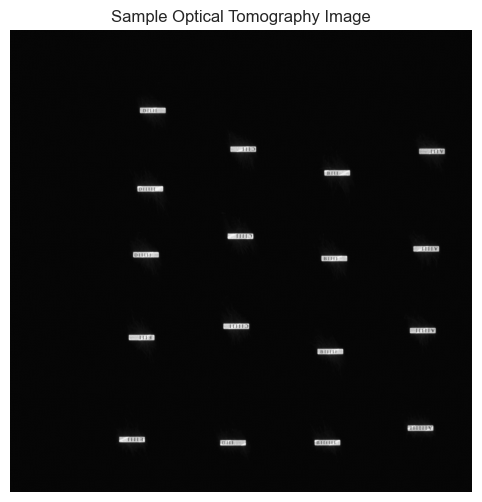

In [2]:
sample_file = next(OT_PATH.glob("*.jpg"))

sample_image = Image.open(sample_file).convert("L")
sample_array = np.array(sample_image)

print("Image:", sample_file.name)
print("Dimensions:", sample_array.shape)
print("Data type:", sample_array.dtype)
print("Minimum intensity:", sample_array.min())
print("Maximum intensity:", sample_array.max())
print("Mean intensity:", sample_array.mean())
print("Standard deviation:", sample_array.std())

plt.figure(figsize=(10, 6))
plt.imshow(sample_array, cmap="gray")
plt.title("Sample Optical Tomography Image")
plt.axis("off")
plt.show()

In [3]:
ot_intensity_data = []

for image_file in tqdm(list(OT_PATH.glob("*.jpg"))):
    image = np.array(Image.open(image_file).convert("L"))

    ot_intensity_data.append({
        "filename": image_file.name,
        "mean_intensity": image.mean(),
        "std_intensity": image.std(),
        "min_intensity": image.min(),
        "max_intensity": image.max(),
        "median_intensity": np.median(image)
    })

ot_intensity_df = pd.DataFrame(ot_intensity_data)

ot_intensity_df.head()

100%|██████████| 2674/2674 [02:43<00:00, 16.40it/s]


,filename,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity
0,SI383820211201123521_1000_039_400_Int_32F.jpg,64.988123,15.406333,58,252,63.0
1,SI383820211201123521_1001_039_440_Int_32F.jpg,64.831706,14.657396,59,250,63.0
2,SI383820211201123521_1002_039_480_Int_32F.jpg,64.921776,14.861544,59,250,63.0
3,SI383820211201123521_1003_039_520_Int_32F.jpg,64.989702,15.451560,59,250,63.0
4,SI383820211201123521_1004_039_560_Int_32F.jpg,64.873702,14.833465,57,250,63.0


In [4]:
ot_intensity_df.describe()

,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity
count,2674.000000,2674.000000,2674.000000,2674.000000,2674.0
mean,66.021508,14.743825,45.390800,246.793568,63.0
std,3.552491,9.658547,14.897914,16.323516,0.0
min,63.000000,0.000000,14.000000,63.000000,63.0
25%,63.697576,7.504106,28.000000,249.000000,63.0
50%,64.335814,10.521534,55.000000,251.000000,63.0
75%,66.450638,19.651997,58.000000,254.000000,63.0
max,79.447918,43.792862,63.000000,255.000000,63.0


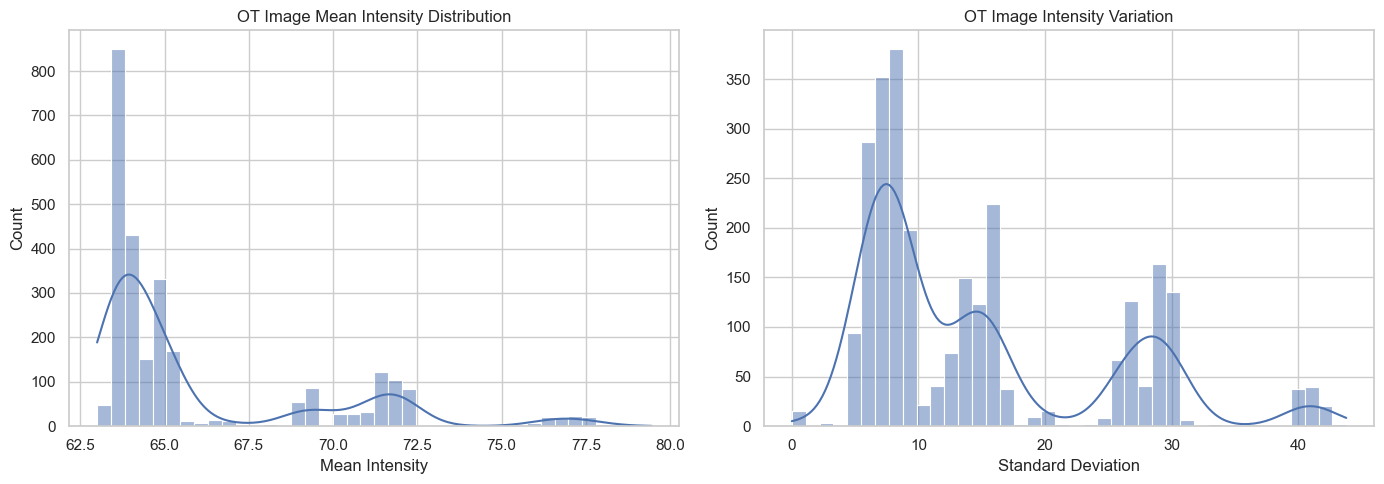

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    ot_intensity_df["mean_intensity"],
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("OT Image Mean Intensity Distribution")
axes[0].set_xlabel("Mean Intensity")

sns.histplot(
    ot_intensity_df["std_intensity"],
    bins=40,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("OT Image Intensity Variation")
axes[1].set_xlabel("Standard Deviation")

plt.tight_layout()
plt.show()

In [6]:
ot_quality_data = []

for image_file in tqdm(list(OT_PATH.glob("*.jpg"))):
    try:
        with Image.open(image_file) as img:
            width, height = img.size
            img.verify()

        ot_quality_data.append({
            "filename": image_file.name,
            "width": width,
            "height": height,
            "file_size_kb": image_file.stat().st_size / 1024,
            "valid": True
        })

    except Exception as e:
        ot_quality_data.append({
            "filename": image_file.name,
            "width": None,
            "height": None,
            "file_size_kb": image_file.stat().st_size / 1024,
            "valid": False
        })

ot_quality_df = pd.DataFrame(ot_quality_data)

ot_quality_df.head()

100%|██████████| 2674/2674 [00:00<00:00, 8215.64it/s]


,filename,width,height,file_size_kb,valid
0,SI383820211201123521_1000_039_400_Int_32F.jpg,2000,2000,78.029297,True
1,SI383820211201123521_1001_039_440_Int_32F.jpg,2000,2000,76.820312,True
2,SI383820211201123521_1002_039_480_Int_32F.jpg,2000,2000,77.842773,True
3,SI383820211201123521_1003_039_520_Int_32F.jpg,2000,2000,78.140625,True
4,SI383820211201123521_1004_039_560_Int_32F.jpg,2000,2000,77.156250,True


In [7]:
print("Total images checked:", len(ot_quality_df))
print("\nValid images:")
print(ot_quality_df["valid"].value_counts())

print("\nImage dimensions:")
print(
    ot_quality_df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

print("\nFile size summary (KB):")
ot_quality_df["file_size_kb"].describe()

Total images checked: 2674

Valid images:
valid
True    2674
Name: count, dtype: int64

Image dimensions:
width  height
2000   2000      2674
dtype: int64

File size summary (KB):


count    2674.000000
mean       89.599055
std        17.458553
min        61.648438
25%        76.237305
50%        83.888672
75%       100.008789
max       153.394531
Name: file_size_kb, dtype: float64

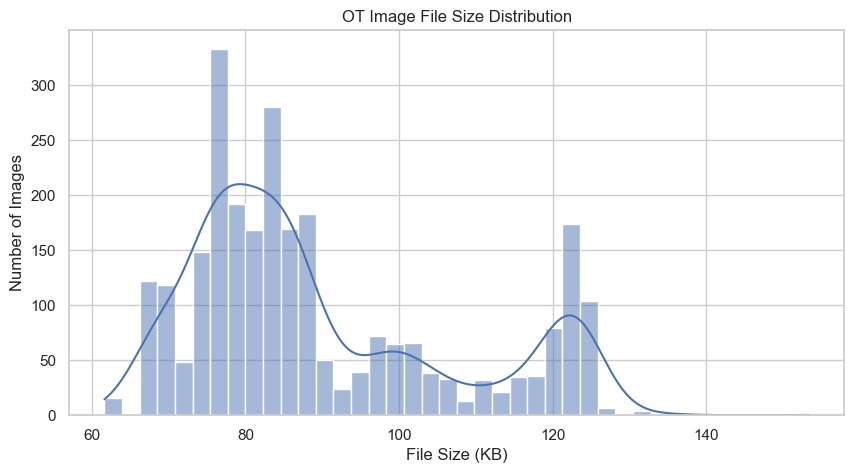

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    ot_quality_df["file_size_kb"],
    bins=40,
    kde=True
)

plt.title("OT Image File Size Distribution")
plt.xlabel("File Size (KB)")
plt.ylabel("Number of Images")
plt.show()

In [10]:
print("Darkest OT images:")
display(
    ot_intensity_df.sort_values("mean_intensity")
    .head(10)
)

print("Brightest OT images:")
display(
    ot_intensity_df.sort_values("mean_intensity", ascending=False)
    .head(10)
)

print("Images with the lowest intensity variation:")
display(
    ot_intensity_df.sort_values("std_intensity")
    .head(10)
)

Darkest OT images:


,filename,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity
1577,SI383820240318120348_1258_026_180_Int_32F.jpg,63.000000,0.000000,63,63,63.0
1589,SI383820240318120348_1269_026_400_Int_32F.jpg,63.000000,0.000000,63,63,63.0
1960,SI383820240318120348_358_008_180_Int_32F.jpg,63.000000,0.000000,63,63,63.0
2293,SI383820240318120348_658_014_180_Int_32F.jpg,63.000000,0.000000,63,63,63.0
2626,SI383820240318120348_958_020_180_Int_32F.jpg,63.000000,0.000000,63,63,63.0
245,SI383820211201123521_30_000_620_Int_32F.jpg,63.006779,0.540154,58,157,63.0
113,SI383820211201123521_18_000_380_Int_32F.jpg,63.007402,0.650886,58,184,63.0
223,SI383820211201123521_28_000_580_Int_32F.jpg,63.007427,0.647549,58,180,63.0
47,SI383820211201123521_12_000_260_Int_32F.jpg,63.007596,0.682915,58,208,63.0
91,SI383820211201123521_16_000_340_Int_32F.jpg,63.007628,0.663787,55,195,63.0


Brightest OT images:


,filename,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity
1224,SI383820240226095904_3_000_080_Int_32F.jpg,79.447918,43.792862,58,251,63.0
1116,SI383820240226095904_1_000_040_Int_32F.jpg,78.719488,41.071061,57,250,63.0
1093,SI383820240226095904_17_000_360_Int_32F.jpg,77.934810,42.256659,59,251,63.0
1290,SI383820240226095904_9_000_200_Int_32F.jpg,77.852824,41.373223,59,250,63.0
1027,SI383820240226095904_11_000_240_Int_32F.jpg,77.845561,42.205321,58,250,63.0
1217,SI383820240226095904_33_000_680_Int_32F.jpg,77.820619,42.071223,58,250,63.0
1270,SI383820240226095904_81_001_640_Int_32F.jpg,77.751370,42.163481,59,250,63.0
1252,SI383820240226095904_65_001_320_Int_32F.jpg,77.737116,42.063664,59,251,63.0
1234,SI383820240226095904_49_001_000_Int_32F.jpg,77.725895,41.980072,58,249,63.0
1226,SI383820240226095904_41_000_840_Int_32F.jpg,77.715976,41.740816,58,250,63.0


Images with the lowest intensity variation:


,filename,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity
1589,SI383820240318120348_1269_026_400_Int_32F.jpg,63.000000,0.000000,63,63,63.0
1577,SI383820240318120348_1258_026_180_Int_32F.jpg,63.000000,0.000000,63,63,63.0
2293,SI383820240318120348_658_014_180_Int_32F.jpg,63.000000,0.000000,63,63,63.0
1960,SI383820240318120348_358_008_180_Int_32F.jpg,63.000000,0.000000,63,63,63.0
2626,SI383820240318120348_958_020_180_Int_32F.jpg,63.000000,0.000000,63,63,63.0
245,SI383820211201123521_30_000_620_Int_32F.jpg,63.006779,0.540154,58,157,63.0
223,SI383820211201123521_28_000_580_Int_32F.jpg,63.007427,0.647549,58,180,63.0
113,SI383820211201123521_18_000_380_Int_32F.jpg,63.007402,0.650886,58,184,63.0
91,SI383820211201123521_16_000_340_Int_32F.jpg,63.007628,0.663787,55,195,63.0
201,SI383820211201123521_26_000_540_Int_32F.jpg,63.007856,0.681057,58,203,63.0


In [11]:
import hashlib

ot_hash_data = []

for image_file in tqdm(list(OT_PATH.glob("*.jpg"))):
    image = np.array(Image.open(image_file).convert("L"))
    image_hash = hashlib.md5(image.tobytes()).hexdigest()

    ot_hash_data.append({
        "filename": image_file.name,
        "hash": image_hash
    })

ot_hash_df = pd.DataFrame(ot_hash_data)

ot_duplicates = ot_hash_df[
    ot_hash_df.duplicated("hash", keep=False)
].sort_values("hash")

print("Images involved in exact duplicate groups:", len(ot_duplicates))
display(ot_duplicates)

100%|██████████| 2674/2674 [01:10<00:00, 38.05it/s]

Images involved in exact duplicate groups: 5


,filename,hash
1577,SI383820240318120348_1258_026_180_Int_32F.jpg,345d03806cc04b7fca992c089a4b6f9f
1589,SI383820240318120348_1269_026_400_Int_32F.jpg,345d03806cc04b7fca992c089a4b6f9f
1960,SI383820240318120348_358_008_180_Int_32F.jpg,345d03806cc04b7fca992c089a4b6f9f
2293,SI383820240318120348_658_014_180_Int_32F.jpg,345d03806cc04b7fca992c089a4b6f9f
2626,SI383820240318120348_958_020_180_Int_32F.jpg,345d03806cc04b7fca992c089a4b6f9f


In [12]:
OUTPUT_PATH = Path("outputs")
OUTPUT_PATH.mkdir(exist_ok=True)

ot_intensity_df.to_csv(
    OUTPUT_PATH / "ot_intensity_statistics.csv",
    index=False
)

ot_quality_df.to_csv(
    OUTPUT_PATH / "ot_image_quality.csv",
    index=False
)

ot_duplicates.to_csv(
    OUTPUT_PATH / "ot_exact_duplicates.csv",
    index=False
)

print("OT EDA results saved to:", OUTPUT_PATH.resolve())

OT EDA results saved to: D:\Capstone\metal additive manufacturing\EDA\outputs


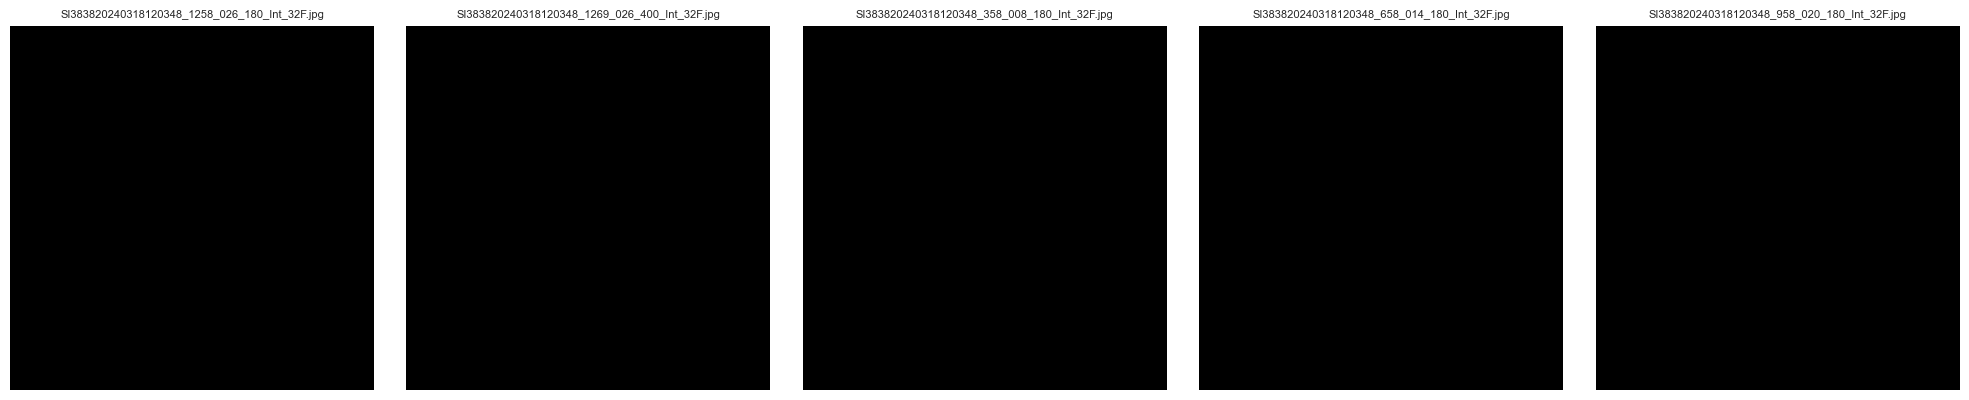

In [13]:
duplicate_filenames = ot_duplicates["filename"].tolist()

fig, axes = plt.subplots(
    1, len(duplicate_filenames),
    figsize=(4 * len(duplicate_filenames), 4)
)

for ax, filename in zip(axes, duplicate_filenames):
    image = np.array(Image.open(OT_PATH / filename).convert("L"))
    ax.imshow(image, cmap="gray")
    ax.set_title(filename, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
for filename in duplicate_filenames:
    image = Image.open(OT_PATH / filename)
    print(filename, image.size)

SI383820240318120348_1258_026_180_Int_32F.jpg (2000, 2000)
SI383820240318120348_1269_026_400_Int_32F.jpg (2000, 2000)
SI383820240318120348_358_008_180_Int_32F.jpg (2000, 2000)
SI383820240318120348_658_014_180_Int_32F.jpg (2000, 2000)
SI383820240318120348_958_020_180_Int_32F.jpg (2000, 2000)


In [15]:
for filename in duplicate_filenames:
    image = np.array(Image.open(OT_PATH / filename).convert("L"))

    print(f"\n{filename}")
    print("Min:", image.min())
    print("Max:", image.max())
    print("Mean:", image.mean())
    print("Std:", image.std())
    print("Unique pixel values:", len(np.unique(image)))


SI383820240318120348_1258_026_180_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1

SI383820240318120348_1269_026_400_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1

SI383820240318120348_358_008_180_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1

SI383820240318120348_658_014_180_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1

SI383820240318120348_958_020_180_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1


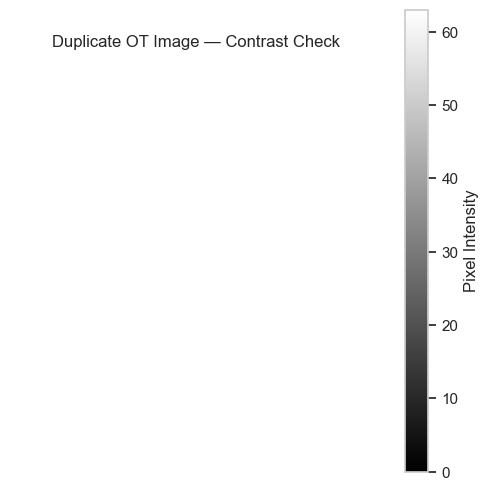

In [16]:
sample_duplicate = np.array(
    Image.open(OT_PATH / duplicate_filenames[0]).convert("L")
)

plt.figure(figsize=(6, 6))
plt.imshow(sample_duplicate, cmap="gray", vmin=0, vmax=max(1, sample_duplicate.max()))
plt.title("Duplicate OT Image — Contrast Check")
plt.colorbar(label="Pixel Intensity")
plt.axis("off")
plt.show()

In [17]:
for filename in duplicate_filenames:
    image = np.array(Image.open(OT_PATH / filename).convert("L"))

    print(f"\n{filename}")
    print("Min:", image.min())
    print("Max:", image.max())
    print("Mean:", image.mean())
    print("Std:", image.std())
    print("Unique pixel values:", len(np.unique(image)))


SI383820240318120348_1258_026_180_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1

SI383820240318120348_1269_026_400_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1

SI383820240318120348_358_008_180_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1

SI383820240318120348_658_014_180_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1

SI383820240318120348_958_020_180_Int_32F.jpg
Min: 63
Max: 63
Mean: 63.0
Std: 0.0
Unique pixel values: 1
